# Esquema escalonado e conservação de massa

O que foi preciso para o modelo a dois fluidos da tese reproduzir a intermitência severa: o esquema de volumes finitos escalonados, o tratamento da fase que desaparece, a formulação conservativa com o balanço verificado pelo acumulador do BDF e a partida bloqueada.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [002](../../docs/issues/002-fv-upwind.md)
- [003](../../docs/issues/003-fase-que-desaparece.md)
- [004](../../docs/issues/004-formulacao-conservativa.md)
- [005](../../docs/issues/005-acumulador-bdf.md)
- [027](../../docs/issues/027-condicoes-iniciais-por-receita.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

In [2]:
from generators.severe_slug import severe_slug_case
from mfsim.analysis import boe_criterion, superficial_velocities
from mfsim.simulation import build_model
from mfsim.results import Results
from mfsim.plotting import surface

DATA = datafile("severe_slug_run.npz")  # corrida histórica v1 (malha 30/10, 8000 s, ~80 min de CPU)
meta = dict(n_down=15, n_riser=5, relax_time=0.05, switch_frac=0.5)
meta.update(json.loads(str(np.load(DATA)["meta"])))
NDOWN, NRISER = meta["n_down"], meta["n_riser"]
TF = 8000.0
case = severe_slug_case(
    method="fv_upwind",
    tf=TF,
    dt_out=2.0,
    qL=qL,
    qG=qG,
    D=D,
    P_out_bar=P_out,
    L_h1=20.0,
    L_down=300.0,
    slope_down_deg=-3.0,
    H_riser=20.0,
    L_h2=5.0,
    n_h1=2,
    n_down=NDOWN,
    n_riser=NRISER,
    n_h2=2,
    regime=4,
    single_pipe=True,
    fluid=fluid,
    roughness=1e-5,
    extra={
        "regime_vertical": 2,
        "q_switch_L": 0.02 * qL,
        "q_switch_G": 0.02 * qG,
        "switch_frac": meta["switch_frac"],
        "relax_time": meta["relax_time"],
    },
)
vSL, vSG = superficial_velocities(case)
m = case.meta
P_base = P_out * 1e5 + 900 * 9.81 * m["H_riser"]
vSL_min, severe = boe_criterion(vSL, vSG, P_base, 900.0, 0.5, m["L_h1"] + m["L_down"])
print(
    f"vSL = {vSL:.3f} m/s, vSG = {vSG:.3f} m/s (à pressão de saída) | critério de Bøe: vSL_min = {vSL_min:.3f} m/s -> severe: {severe}"
)
print(
    "(Bøe na forma de Taitel 1986 / Jansen 1996: vSL >= P vSG / (rhoL g (1 - alphaG) L), sem fator de inclinação; L = linha de entrada + descendente)"
)
model = build_model(case)

vSL = 0.296 m/s, vSG = 0.124 m/s (à pressão de saída) | critério de Bøe: vSL_min = 0.050 m/s -> severe: True
(Bøe na forma de Taitel 1986 / Jansen 1996: vSL >= P vSG / (rhoL g (1 - alphaG) L), sem fator de inclinação; L = linha de entrada + descendente)


In [3]:
d = np.load(DATA)
T, X = d["T"], d["X"]
print("trajetória carregada:", os.path.basename(DATA), "até t =", T[-1])
res = Results(model, T, X)
p = res.pipe(0)
x = p["x"]
aG = p["out"]["alphaG"]
P = p["out"]["P_bar"]
qLo = p["out"]["qL"]
qGo = p["out"]["qG"]
ib = int(np.argmin(np.abs(x - (m["L_h1"] + m["L_down"]))))

trajetória carregada: severe_slug_run.npz até t = 8000.0


## Verificação do balanço de massa de líquido
Estoque de líquido no duto (a partir dos estados gravados) contra a integral de
(entrada − saída) pela regra dos trapézios nas saídas de 2 s. O descolamento em
degraus, um por *blowdown*, é a deriva de massa da integração nas variáveis
primitivas (αG, P); a última seção deste notebook repete o caso com a formulação
conservativa e com a integral dos fluxos consistente com o BDF.

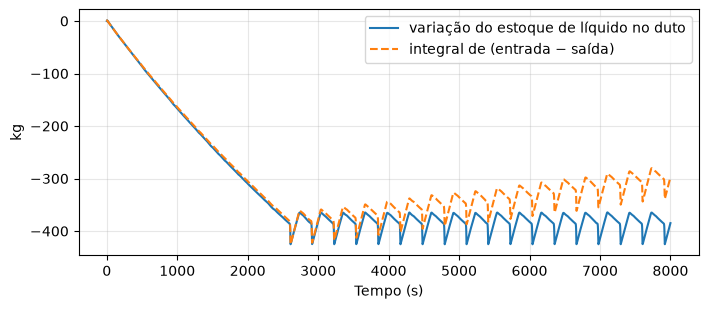

erro final de massa: -87.6 kg (estoque inicial 607.1 kg, entrada acumulada 4241 kg)


In [4]:
h = model.pipes[0].mesh["h"]
mass = np.sum((1 - aG[1:-1]) * fluid.rhoL(P[1:-1] * 1e5) * A * h[:, None], axis=0)
net = np.concatenate([[0.0], np.cumsum(0.5 * ((qLo[0, 1:] - qLo[-1, 1:]) + (qLo[0, :-1] - qLo[-1, :-1])) * np.diff(T))])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(T, mass - mass[0], label="variação do estoque de líquido no duto")
ax.plot(T, net, "--", label="integral de (entrada − saída)")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("kg")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(
    f"erro final de massa: {mass[-1]-mass[0]-net[-1]:.1f} kg (estoque inicial {mass[0]:.1f} kg, entrada acumulada {qL*T[-1]:.0f} kg)"
)

## Pressões e vazões de saída

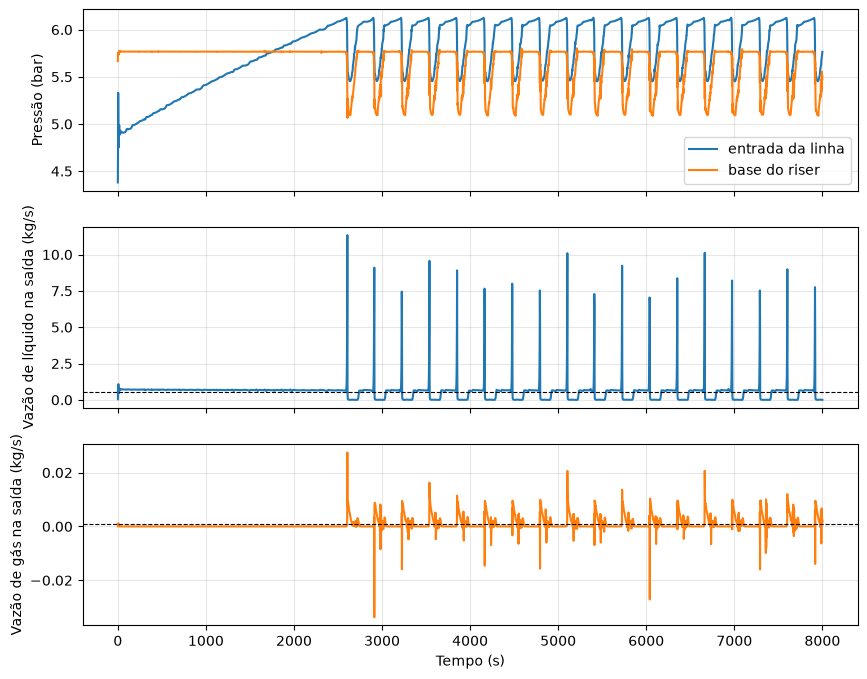

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(T, P[1], label="entrada da linha")
axes[0].plot(T, P[ib], label="base do riser")
axes[0].set_ylabel("Pressão (bar)")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(T, qLo[-1])
axes[1].axhline(qL, color="k", ls="--", lw=0.8)
axes[1].set_ylabel("Vazão de líquido na saída (kg/s)")
axes[1].grid(alpha=0.3)
axes[2].plot(T, qGo[-1], color="C1")
axes[2].axhline(qG, color="k", ls="--", lw=0.8)
axes[2].set_ylabel("Vazão de gás na saída (kg/s)")
axes[2].set_xlabel("Tempo (s)")
axes[2].grid(alpha=0.3)
plt.show()

## Fração de gás ao longo do duto

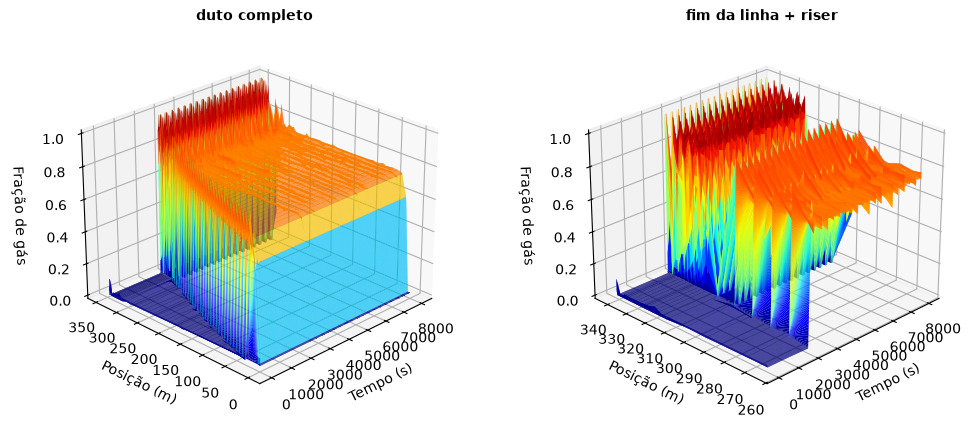

In [6]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
surface(ax, x, T, aG, zlabel="Fração de gás", title="duto completo")
ax = fig.add_subplot(1, 2, 2, projection="3d")
sl = slice(max(ib - 6, 0), ib + NRISER + 1)
surface(ax, x[sl], T, aG[sl], zlabel="Fração de gás", title="fim da linha + riser")
plt.show()

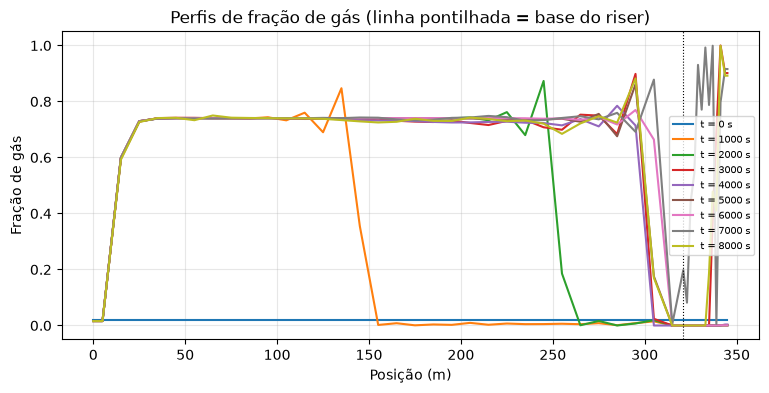

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for t in np.linspace(0, T[-1], 9):
    it = int(np.argmin(np.abs(T - t)))
    ax.plot(x, aG[:, it], label=f"t = {T[it]:.0f} s")
ax.axvline(x[ib], color="k", lw=0.8, ls=":")
ax.set_xlabel("Posição (m)")
ax.set_ylabel("Fração de gás")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)
ax.set_title("Perfis de fração de gás (linha pontilhada = base do riser)")
plt.show()

## Ciclos em detalhe e período
Na fase de bloqueio o riser está cheio de líquido e a pressão da linha sobe
lentamente; quando o gás atinge a base do riser, a coluna é expelida (*blowdown*):
a fração de gás no riser passa de 0 a ~0.9 em cerca de 20 s e a vazão de líquido na
saída atinge 10–20 vezes a alimentação; em seguida o riser volta a encher e o ciclo
recomeça.

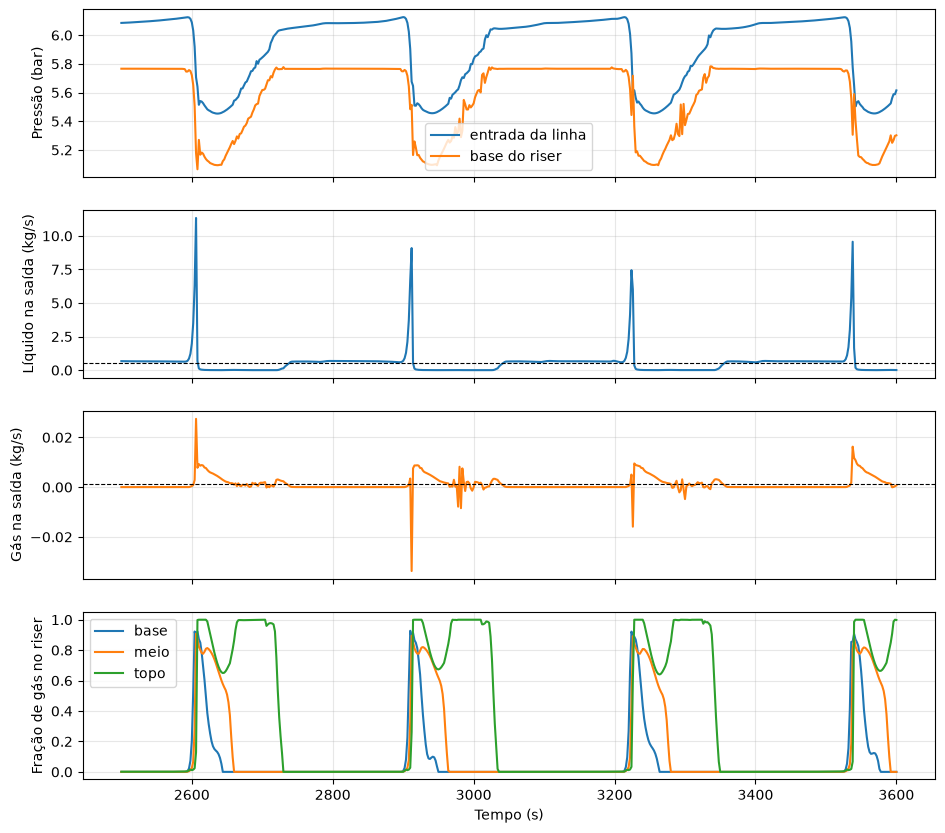

instantes dos picos de líquido (s): [2606, 2912, 3224, 3538, 3852, 4164, 4478, 4792, 5104, 5410, 5726, 6038, 6352, 6664, 6974, 7290, 7602, 7916]
período médio ≈ 312 s; pico máximo 11.3 kg/s (21x a alimentação)


In [8]:
sel = (T >= 2500) & (T <= 3600)  # janela com ~4 ciclos
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
axes[0].plot(T[sel], P[1][sel], label="entrada da linha")
axes[0].plot(T[sel], P[ib][sel], label="base do riser")
axes[0].set_ylabel("Pressão (bar)")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(T[sel], qLo[-1][sel])
axes[1].axhline(qL, color="k", ls="--", lw=0.8)
axes[1].set_ylabel("Líquido na saída (kg/s)")
axes[1].grid(alpha=0.3)
axes[2].plot(T[sel], qGo[-1][sel], color="C1")
axes[2].axhline(qG, color="k", ls="--", lw=0.8)
axes[2].set_ylabel("Gás na saída (kg/s)")
axes[2].grid(alpha=0.3)
axes[3].plot(T[sel], aG[ib + 1][sel], label="base")
axes[3].plot(T[sel], aG[ib + NRISER // 2][sel], label="meio")
axes[3].plot(T[sel], aG[ib + NRISER][sel], label="topo")
axes[3].set_ylabel("Fração de gás no riser")
axes[3].legend()
axes[3].set_xlabel("Tempo (s)")
axes[3].grid(alpha=0.3)
plt.show()
peaks = [
    i for i in range(1, T.size - 1) if qLo[-1, i] > 2.0 and qLo[-1, i] >= qLo[-1, i - 1] and qLo[-1, i] > qLo[-1, i + 1]
]
if len(peaks) > 1:
    tp = T[peaks]
    print("instantes dos picos de líquido (s):", np.round(tp).astype(int).tolist())
    print(
        f"período médio ≈ {np.mean(np.diff(tp)):.0f} s; pico máximo {qLo[-1].max():.1f} kg/s ({qLo[-1].max()/qL:.0f}x a alimentação)"
    )

## Simulação longa (8000 s, malha mais grossa)
Trajetória gravada em `data/severe_slug_run_long.npz` (15 células no trecho
descendente e 5 no riser, tolerância relativa 3e-3, ~50 min de CPU), para
comparação com a malha fina acima. A malha mais grossa encurta o período
(≈ 230 s contra ≈ 312 s) e reduz a altura dos picos, mas preserva o mecanismo:
pressurização lenta, *blowdown* abrupto, pico de produção e reenchimento. O
erro acumulado de massa é mostrado para avaliar a qualidade da solução
(≈ 2.6 % do líquido alimentado em 8000 s; ≈ 2.1 % na malha fina).

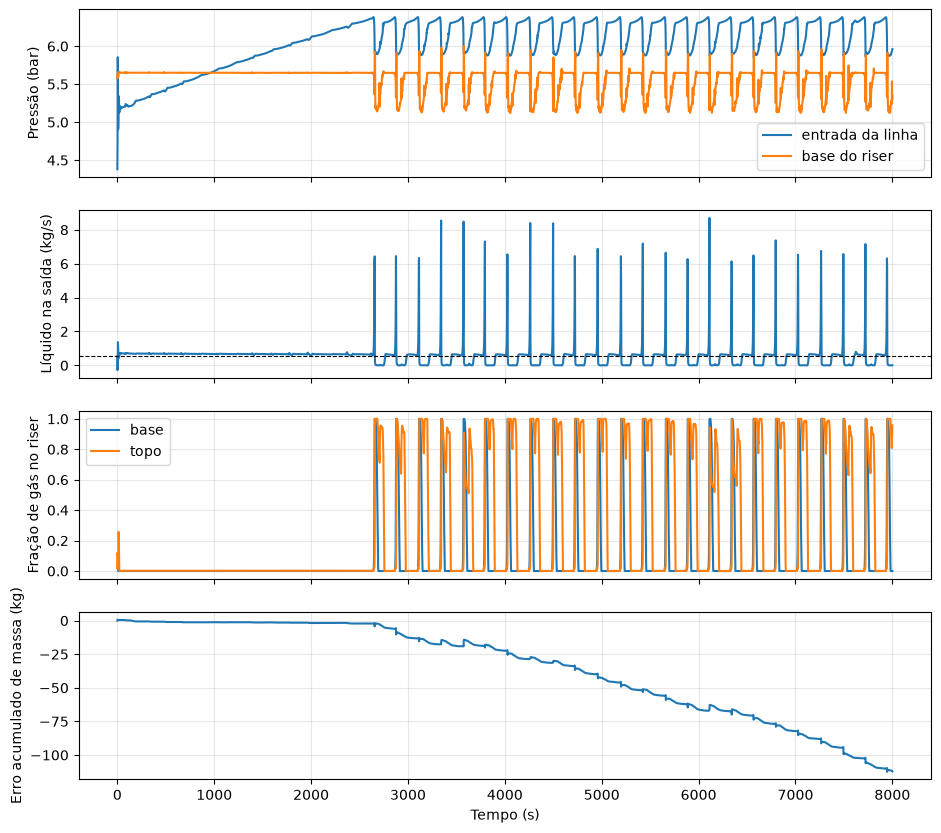

picos (s): [2656, 2876, 3114, 3342, 3574, 3794, 4026, 4262, 4498, 4722, 4958, 5198, 5424, 5660, 5886, 6112, 6340, 6566, 6796, 7026, 7264, 7494, 7722, 7944] | período médio ≈ 230 s | pico máximo 8.7 kg/s
erro final de massa: -112.1 kg em 4241 kg alimentados


In [9]:
DATA_LONG = datafile("severe_slug_run_long.npz")
if DATA_LONG:
    dl = np.load(DATA_LONG)
    Tl_, Xl_ = dl["T"], dl["X"]
    ml = json.loads(str(dl["meta"]))
    case_l = severe_slug_case(
        method="fv_upwind",
        tf=Tl_[-1],
        dt_out=2.0,
        qL=qL,
        qG=qG,
        D=D,
        P_out_bar=P_out,
        L_h1=20.0,
        L_down=300.0,
        slope_down_deg=-3.0,
        H_riser=20.0,
        L_h2=5.0,
        n_h1=2,
        n_down=ml["n_down"],
        n_riser=ml["n_riser"],
        n_h2=2,
        regime=4,
        single_pipe=True,
        fluid=fluid,
        roughness=1e-5,
        extra={
            "regime_vertical": 2,
            "q_switch_L": 0.02 * qL,
            "q_switch_G": 0.02 * qG,
            "switch_frac": ml["switch_frac"],
            "relax_time": ml["relax_time"],
        },
    )
    model_l = build_model(case_l)
    res_l = Results(model_l, Tl_, Xl_)
    pl = res_l.pipe(0)
    xl = pl["x"]
    aGl = pl["out"]["alphaG"]
    Pl = pl["out"]["P_bar"]
    qLl = pl["out"]["qL"]
    ibl = int(np.argmin(np.abs(xl - (m["L_h1"] + m["L_down"]))))
    hl = model_l.pipes[0].mesh["h"]
    mass_l = np.sum((1 - aGl[1:-1]) * fluid.rhoL(Pl[1:-1] * 1e5) * A * hl[:, None], axis=0)
    net_l = np.concatenate(
        [[0.0], np.cumsum(0.5 * ((qLl[0, 1:] - qLl[-1, 1:]) + (qLl[0, :-1] - qLl[-1, :-1])) * np.diff(Tl_))]
    )
    fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
    axes[0].plot(Tl_, Pl[1], label="entrada da linha")
    axes[0].plot(Tl_, Pl[ibl], label="base do riser")
    axes[0].set_ylabel("Pressão (bar)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(Tl_, qLl[-1])
    axes[1].axhline(qL, color="k", ls="--", lw=0.8)
    axes[1].set_ylabel("Líquido na saída (kg/s)")
    axes[1].grid(alpha=0.3)
    axes[2].plot(Tl_, aGl[ibl + 1], label="base")
    axes[2].plot(Tl_, aGl[ibl + ml["n_riser"]], label="topo")
    axes[2].set_ylabel("Fração de gás no riser")
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    axes[3].plot(Tl_, mass_l - mass_l[0] - net_l)
    axes[3].set_ylabel("Erro acumulado de massa (kg)")
    axes[3].set_xlabel("Tempo (s)")
    axes[3].grid(alpha=0.3)
    plt.show()
    pk = [
        i
        for i in range(1, Tl_.size - 1)
        if qLl[-1, i] > 2.0 and qLl[-1, i] >= qLl[-1, i - 1] and qLl[-1, i] > qLl[-1, i + 1]
    ]
    if len(pk) > 1:
        print(
            "picos (s):",
            np.round(Tl_[pk]).astype(int).tolist(),
            f"| período médio ≈ {np.mean(np.diff(Tl_[pk])):.0f} s | pico máximo {qLl[-1].max():.1f} kg/s",
        )
    print(f"erro final de massa: {mass_l[-1]-mass_l[0]-net_l[-1]:.1f} kg em {qL*Tl_[-1]:.0f} kg alimentados")
else:
    print("trajetória longa não encontrada")

## Partida "bloqueada" e dois conjuntos de variáveis de estado

Para não esperar ~2500 s pelo primeiro ciclo, o caso também é iniciado numa
condição construída (`start="blocked"`): bolsão de gás no trecho descendente com a
fração de equilíbrio estratificado (αG ≈ 0.75), riser cheio de líquido,
hidrostática em cada trecho e um salto de pressão na frente do bolsão (margem de
0.3 bar sobre a coluna do riser). O primeiro *blowdown* ocorre em ~12 s e o ciclo
limite é atingido em poucos períodos.

A mesma trajetória (malha grossa, 15 + 5 células, tolerância 3e-3) é calculada
com dois conjuntos de variáveis de estado nas células:

1. **primitivas** (αG, P): as equações de massa são integradas na forma
   quase-linear dαG/dt, dP/dt (como na tese). A conservação de massa é apenas
   aproximada: o erro de truncamento das equações de massa não é cumulativo por
   construção e o limitador de fração de gás nos limites 0/1 descarta massa; o
   erro concentra-se nos *blowdowns* (alguns kg por ciclo).
2. **resíduo conservativo**: o BDF é aplicado às massas por volume
   T(x) = (ρG αG, ρL αL) — resíduo T(x_{n+1}) − Σ a_j T(x_{n−j}) − γ h f(x_{n+1}) = 0,
   resolvido por Newton nas mesmas variáveis primitivas (dT/dx analítica). Os fluxos
   de massa nas faces são multiplicados por um limitador da célula doadora (fluxo
   nulo quando a célula a montante não tem a fase), o que garante positividade sem
   o limitador de fração de gás e mantém o balanço **exato** por célula a cada
   passo. Como T é singular em αG = −γG/γL ≈ −0.01, os limites admitidos para αG são
   [−0.005, 1.005] (um pequeno *undershoot* evita projeções do Newton em 0).

Custo: no modo conservativo a pressão é escrava da massa de líquido através da
compressibilidade (δP/P = γL δmL/mL): o erro de truncamento da massa aparece como
"ruído" de pressão e o controle de passo responde com passos menores (cerca de
2 vezes mais passos nas fases de *blowdown*). Nas variáveis primitivas a pressão é
suave e o mesmo erro de truncamento vira a deriva de massa.

**Como o balanço é verificado.** A integral de (entrada − saída) pela regra dos
trapézios nas saídas gravadas a cada 2 s não é exata (os picos de vazão duram
segundos e os estados gravados são interpolados), por isso o integrador também
acumula os fluxos de contorno com a **mesma recorrência BDF** dos estados
(I_{n+1} = w1 I_n + w2 I_{n−1} + γh g(x_{n+1}), `ImplicitBDF.accum`). Para a
formulação conservativa, estoque(t) − estoque(0) − I(t) é zero a menos de
arredondamento, por construção; para a formulação primitiva a mesma quantidade é
a deriva real de massa da integração.

In [10]:
from mfsim.runs import load_run
from mfsim.analysis import mass_balance


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )


runs = {}
for tag, fname in (
    ("primitivas", "severe_slug_blocked_primitive.npz"),
    ("conservativo", "severe_slug_blocked_conservative.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs[tag] = load_blocked_run(f)
    mb = runs[tag]["meta"]
    print(f"{tag:13s}: {mb['n_steps']} passos, {mb['n_rejected']} rejeitados, {mb['cpu']/60:.0f} min de CPU")

primitivas   : 91783 passos, 24105 rejeitados, 18 min de CPU


conservativo : 132679 passos, 39681 rejeitados, 25 min de CPU


### Condição inicial construída

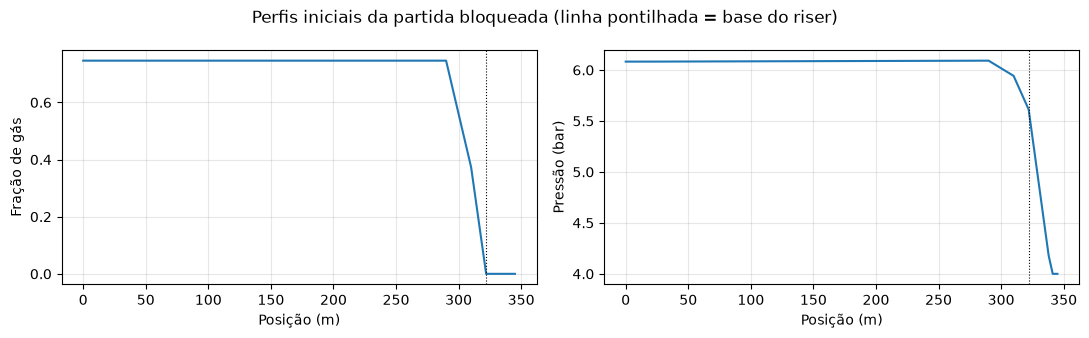

In [11]:
if runs:
    r0 = next(iter(runs.values()))
    p0 = r0["p"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(p0["x"], p0["out"]["alphaG"][:, 0])
    axes[0].set_ylabel("Fração de gás")
    axes[0].set_xlabel("Posição (m)")
    axes[1].plot(p0["x"], p0["out"]["P_bar"][:, 0])
    axes[1].set_ylabel("Pressão (bar)")
    axes[1].set_xlabel("Posição (m)")
    for ax in axes:
        ax.axvline(p0["x"][r0["ib"]], color="k", lw=0.8, ls=":")
        ax.grid(alpha=0.3)
    fig.suptitle("Perfis iniciais da partida bloqueada (linha pontilhada = base do riser)")
    fig.tight_layout()
    plt.show()

### Produção, pressão e balanço de massa nas duas formulações

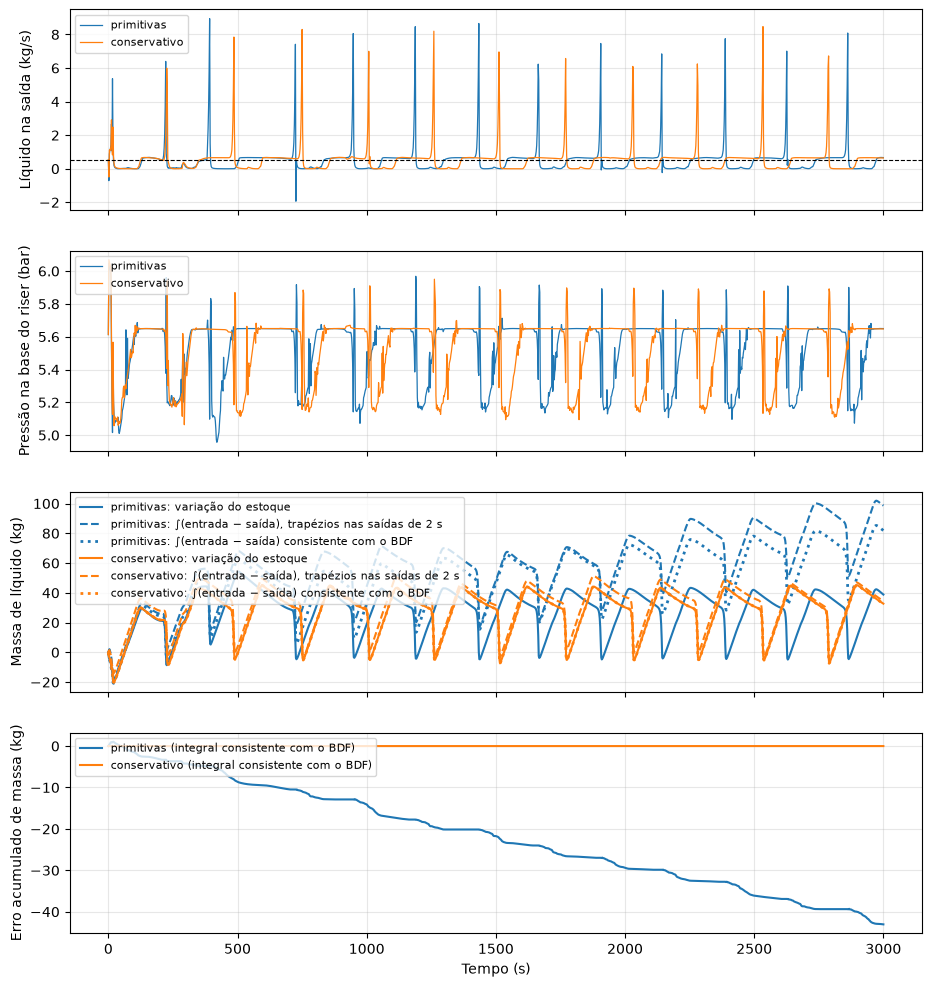

primitivas   : 12 blowdowns, primeiro em 18 s, período médio ≈ 259 s, pico máximo 8.9 kg/s
   erro de massa (trapézios nas saídas de 2 s): líquido -59.74 kg (-3.76 % do alimentado), gás +0.3588 kg (+10.96 %)
   erro de massa (integral consistente com o BDF):   líquido -4.30e+01 kg (-2.71e+00 %), gás +2.78e-01 kg (+8.48e+00 %)
conservativo : 12 blowdowns, primeiro em 20 s, período médio ≈ 254 s, pico máximo 8.5 kg/s
   erro de massa (trapézios nas saídas de 2 s): líquido -1.74 kg (-0.11 % do alimentado), gás +0.2096 kg (+6.40 %)
   erro de massa (integral consistente com o BDF):   líquido -1.14e-05 kg (-7.16e-07 %), gás -7.19e-08 kg (-2.20e-06 %)


In [12]:
if runs:
    fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
    for k, (tag, r) in enumerate(runs.items()):
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        massL, netL, errL = r["balL"]
        axes[0].plot(T_, p_["out"]["qL"][-1], color=f"C{k}", lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][ib_], color=f"C{k}", lw=0.9, label=tag)
        axes[2].plot(T_, massL - massL[0], color=f"C{k}", label=f"{tag}: variação do estoque")
        axes[2].plot(T_, netL, "--", color=f"C{k}", label=f"{tag}: ∫(entrada − saída), trapézios nas saídas de 2 s")
        if r["acc"] is not None:
            axes[2].plot(
                T_, r["acc"][0], ":", color=f"C{k}", lw=2, label=f"{tag}: ∫(entrada − saída) consistente com o BDF"
            )
            axes[3].plot(
                T_, massL - massL[0] - r["acc"][0], color=f"C{k}", label=f"{tag} (integral consistente com o BDF)"
            )
        else:
            axes[3].plot(T_, errL, color=f"C{k}", label=f"{tag} (trapézios)")
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na base do riser (bar)")
    axes[2].set_ylabel("Massa de líquido (kg)")
    axes[3].set_ylabel("Erro acumulado de massa (kg)")
    axes[3].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper left")
    plt.show()
    for tag, r in runs.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        massL, netL, errL = r["balL"]
        massG, netG, errG = r["balG"]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        print(
            f"{tag:13s}: {nb_} blowdowns, primeiro em {blowdowns(T_, r['p']['out']['P_bar'][1])[0]:.0f} s, período médio ≈ {per:.0f} s, pico máximo {qmax:.1f} kg/s"
        )
        print(
            f"   erro de massa (trapézios nas saídas de 2 s): líquido {errL[-1]:+.2f} kg ({100*errL[-1]/(qL*T_[-1]):+.2f} % do alimentado), gás {errG[-1]:+.4f} kg ({100*errG[-1]/(qG*T_[-1]):+.2f} %)"
        )
        if r["acc"] is not None:
            eL = massL[-1] - massL[0] - r["acc"][0, -1]
            eG = massG[-1] - massG[0] - r["acc"][1, -1]
            print(
                f"   erro de massa (integral consistente com o BDF):   líquido {eL:+.2e} kg ({100*eL/(qL*T_[-1]):+.2e} %), gás {eG:+.2e} kg ({100*eG/(qG*T_[-1]):+.2e} %)"
            )

### Detalhe de um ciclo nas duas formulações

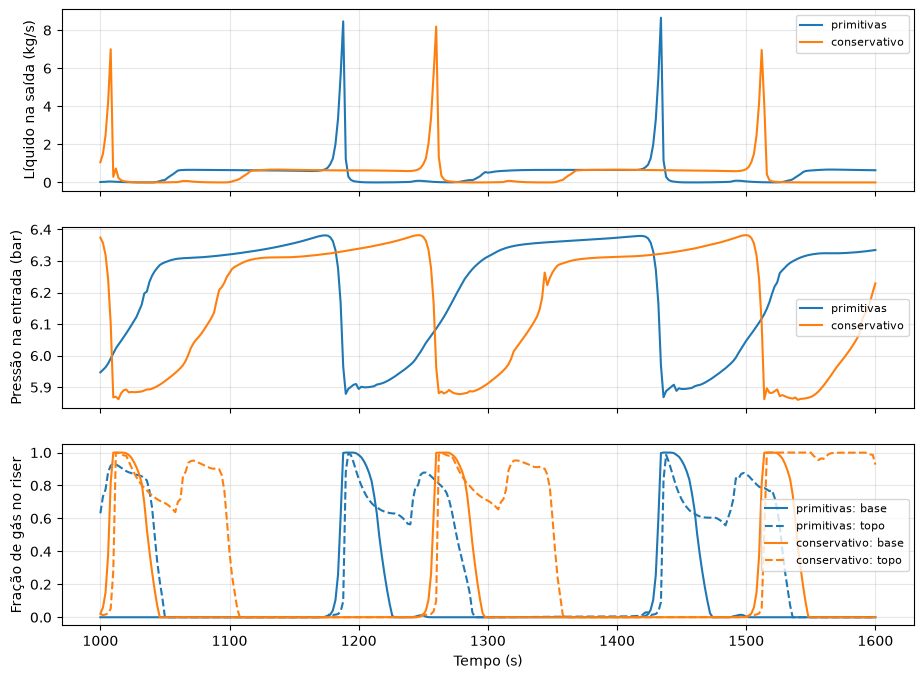

In [13]:
if len(runs) == 2:
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for k, (tag, r) in enumerate(runs.items()):
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        sel = (T_ >= 1000) & (T_ <= 1600)
        axes[0].plot(T_[sel], p_["out"]["qL"][-1][sel], color=f"C{k}", label=tag)
        axes[1].plot(T_[sel], p_["out"]["P_bar"][1][sel], color=f"C{k}", label=tag)
        axes[2].plot(T_[sel], p_["out"]["alphaG"][ib_ + 1][sel], color=f"C{k}", label=f"{tag}: base")
        axes[2].plot(
            T_[sel], p_["out"]["alphaG"][ib_ + r["meta"]["n_riser"]][sel], "--", color=f"C{k}", label=f"{tag}: topo"
        )
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[2].set_ylabel("Fração de gás no riser")
    axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.show()